## Exponential Smoothing for Stock Price Forecasting

This notebook applies Exponential Smoothing methods to forecast RELIANCE stock closing prices and compares their performance using MAE, MSE, and RMSE.

In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    ExponentialSmoothing
)

from sklearn.metrics import mean_absolute_error, mean_squared_error

### Load Dataset

Load the preprocessed RELIANCE stock data and prepare the closing-price time series.

In [14]:
from pathlib import Path
import pandas as pd

cwd = Path.cwd().resolve()
search_dirs = [cwd, *cwd.parents]
search_dirs.extend(path for path in cwd.iterdir() if path.is_dir())

processed_path = None
for base in search_dirs:
    candidate = base / "data" / "processed" / "RELIANCE_processed.csv"
    if candidate.is_file():
        processed_path = candidate
        break

if processed_path is None:
    raise FileNotFoundError(
        "Could not find data/processed/RELIANCE_processed.csv. "
        f"Jupyter's current directory is: {cwd}. "
        "Open the notebook from inside the stock-price-forecasting project, "
        "or update the path to your project's processed CSV."
    )

df = pd.read_csv(processed_path, parse_dates=["Date"])
df = df.sort_values("Date")
df = df.drop_duplicates(subset="Date")
df = df.set_index("Date")

series = pd.to_numeric(df["Close"], errors="coerce").dropna()
series = series.sort_index()

series = series.asfreq("B").ffill()

print("Dataset loaded successfully!")
print("Loaded from:", processed_path)
print("Dataset size:", len(series))
print("Start date:", series.index.min())
print("End date:", series.index.max())

display(series.head())


Dataset loaded successfully!
Loaded from: C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\data\processed\RELIANCE_processed.csv
Dataset size: 3049
Start date: 2015-01-30 00:00:00
End date: 2026-10-07 00:00:00


Date
2015-01-30    209.210754
2015-02-02    207.564957
2015-02-03    214.319595
2015-02-04    212.308060
2015-02-05    211.142288
Freq: B, Name: Close, dtype: float64

### Closing Price Trend

Visualize the historical closing prices to understand their overall movement.

In [15]:
from pathlib import Path
import pandas as pd

filename = "RELIANCE_processed.csv"
cwd = Path.cwd().resolve()

data_file = next((
        folder / "data" / "processed" / filename
        for folder in [cwd, *cwd.parents]
        if (folder / "data" / "processed" / filename).is_file()
    ),None)

if data_file is None:
    raise FileNotFoundError(
        f"Could not find {filename}.\n"
        f"Current working directory: {cwd}\n"
        "Check that the CSV exists inside data/processed/."
    )

df = pd.read_csv(data_file, parse_dates=["Date"])

print("Dataset loaded successfully!")
print("File location:", data_file)
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
File location: C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\data\processed\RELIANCE_processed.csv
Shape: (2890, 18)


,index,Date,Adj Close,Close,High,Low,Open,Volume,Target,lag1,lag2,lag3,lag5,lag10,Return,MA5,MA20,Volatility20
0,20,2015-01-30,194.951019,209.210754,212.868088,207.782104,212.582352,21746801,207.564957,212.445206,207.290649,203.221878,202.010391,197.553009,-0.015225,206.979782,200.206291,0.020023
1,21,2015-02-02,193.417374,207.564957,210.273666,207.027786,209.393616,19302710,214.319595,209.210754,212.445206,207.290649,202.730423,198.798798,-0.007867,207.946689,200.463448,0.020116
2,22,2015-02-03,199.711624,214.319595,215.062485,208.742157,208.742157,17092333,212.308060,207.564957,209.210754,212.445206,203.221878,201.073196,0.032542,210.166232,201.169199,0.021035
3,23,2015-02-04,197.837219,212.308060,215.736801,211.645172,214.662460,14072894,211.142288,214.319595,207.564957,209.210754,207.290649,206.422043,-0.009386,211.169714,202.228682,0.017932
4,24,2015-02-05,196.750900,211.142288,214.845322,209.747925,213.953857,12365643,207.987839,212.308060,214.319595,207.564957,212.445206,207.267792,-0.005491,210.909131,203.021866,0.017659


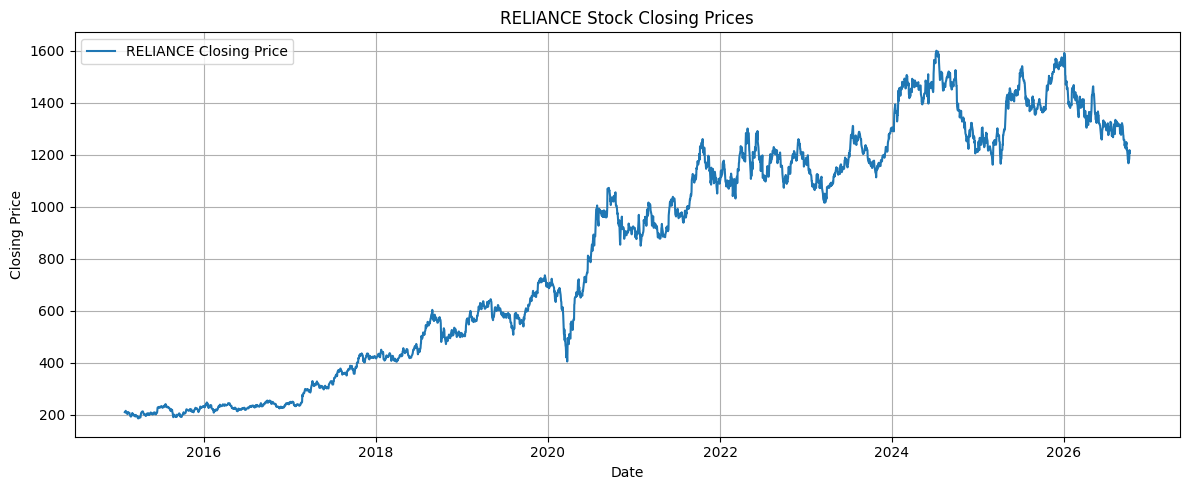

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(series, label="RELIANCE Closing Price")

plt.title("RELIANCE Stock Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Train-Test Split

Use the first 80% of observations for training and the remaining 20% for testing, preserving chronological order.

In [17]:
split_index = int(len(series) * 0.8)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train.index[-1])
print("Testing starts:", test.index[0])

Training observations: 2439
Testing observations: 610
Training ends: 2024-06-05 00:00:00
Testing starts: 2024-06-06 00:00:00


### Simple Exponential Smoothing

SES gives more weight to recent observations and models the series without an explicit trend component.

In [18]:
ses_model = SimpleExpSmoothing(
    train,
    initialization_method="estimated"
).fit(optimized=True)

ses_forecast = ses_model.forecast(len(test))
ses_forecast.index = test.index

print("Simple Exponential Smoothing completed.")

Simple Exponential Smoothing completed.


### Holt Linear Trend

Holt's method models both the level and the trend using an additive trend component.

In [19]:
holt_model = ExponentialSmoothing(
    train,
    trend="add",
    initialization_method="estimated"
).fit(optimized=True)

holt_forecast = holt_model.forecast(len(test))
holt_forecast.index = test.index

print("Holt Linear Trend completed.")

Holt Linear Trend completed.


### Holt Damped Trend

The damped trend method gradually reduces the influence of the trend over longer forecast horizons.

In [20]:
damped_model = ExponentialSmoothing(
    train,
    trend="add",
    damped_trend=True,
    initialization_method="estimated"
).fit(optimized=True)

damped_forecast = damped_model.forecast(len(test))
damped_forecast.index = test.index

print("Holt Damped Trend completed.")

Holt Damped Trend completed.


### Model Evaluation

Compare the forecasts against actual test prices using MAE, MSE, and RMSE. Lower errors indicate better performance on this test set.

In [21]:
forecasts = {
    "Simple Exponential Smoothing": ses_forecast,
    "Holt Linear Trend": holt_forecast,
    "Holt Damped Trend": damped_forecast
}

results = []

for model_name, forecast in forecasts.items():
    mae = mean_absolute_error(test, forecast)
    mse = mean_squared_error(test, forecast)
    rmse = np.sqrt(mse)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE").reset_index(drop=True)

display(results_df)

best_model_name = results_df.loc[0, "Model"]

print("Best model based on test RMSE:", best_model_name)

,Model,MAE,MSE,RMSE
0,Holt Damped Trend,92.857684,12429.268406,111.486629
1,Simple Exponential Smoothing,92.857696,12429.271840,111.486644
2,Holt Linear Trend,208.876577,58836.089029,242.561516


Best model based on test RMSE: Holt Damped Trend


### Actual vs Predicted Prices

Compare the actual test-period closing prices with predictions from the three models.

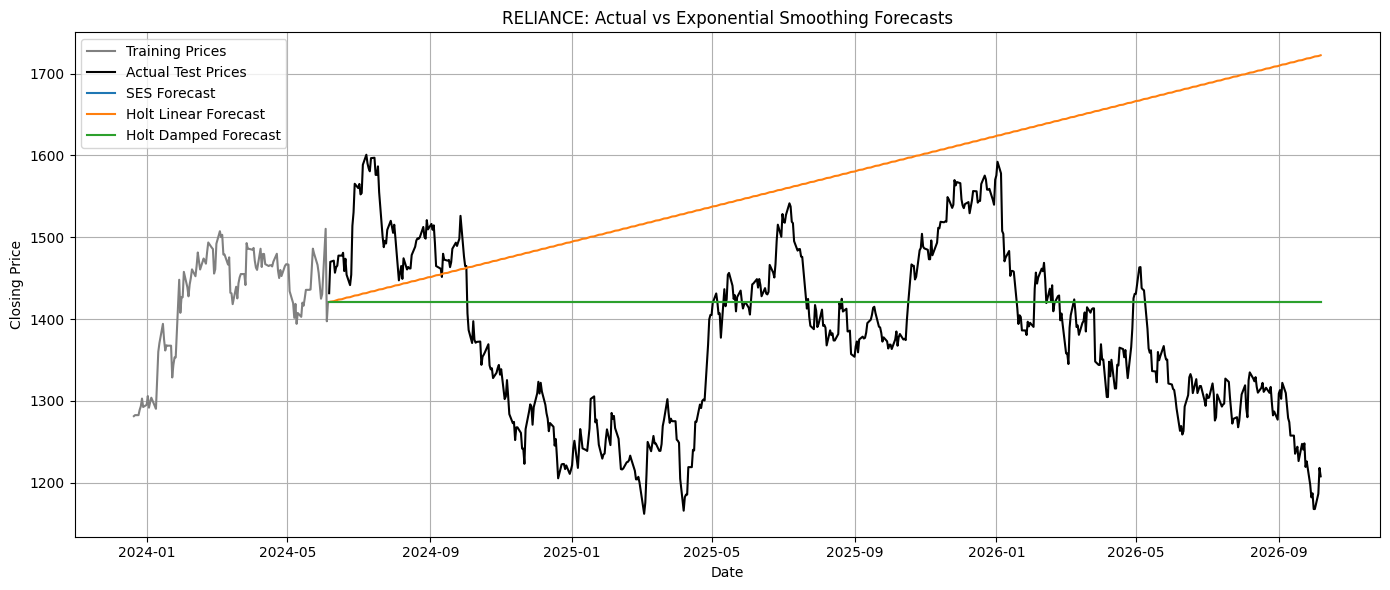

In [22]:
plt.figure(figsize=(14, 6))

# Display recent training data for context
plt.plot(
    train.iloc[-120:],
    label="Training Prices",
    color="gray"
)

plt.plot(test, label="Actual Test Prices", color="black")
plt.plot(ses_forecast, label="SES Forecast")
plt.plot(holt_forecast, label="Holt Linear Forecast")
plt.plot(damped_forecast, label="Holt Damped Forecast")

plt.title("RELIANCE: Actual vs Exponential Smoothing Forecasts")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### RMSE Comparison

Visualize the test RMSE values to compare the models' prediction errors.

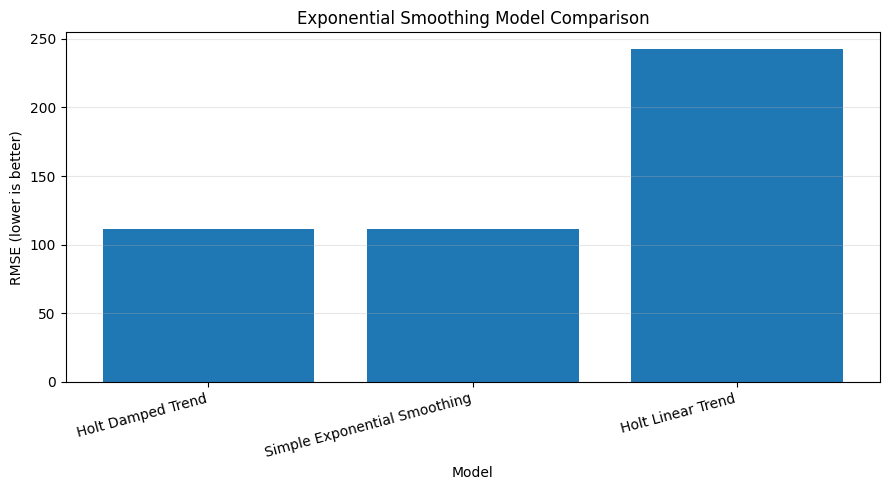

In [23]:
plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["RMSE"])

plt.title("Exponential Smoothing Model Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Export Results

Save the evaluation metrics and test-period forecasts as CSV files.

In [24]:
forecast_results = pd.DataFrame({
    "Actual": test,
    "SES_Forecast": ses_forecast,
    "Holt_Linear_Forecast": holt_forecast,
    "Holt_Damped_Forecast": damped_forecast
})

forecast_results.index.name = "Date"

forecast_results.to_csv("exponential_smoothing_forecasts.csv")
results_df.to_csv("exponential_smoothing_metrics.csv", index=False)

print("Saved: exponential_smoothing_forecasts.csv")
print("Saved: exponential_smoothing_metrics.csv")

Saved: exponential_smoothing_forecasts.csv
Saved: exponential_smoothing_metrics.csv


### Next Business-Day Forecast

Refit the best-performing model on all available data and generate a one-step-ahead estimate.

In [25]:
if best_model_name == "Simple Exponential Smoothing":
    final_model = SimpleExpSmoothing(
        series,
        initialization_method="estimated"
    ).fit(optimized=True)

elif best_model_name == "Holt Linear Trend":
    final_model = ExponentialSmoothing(
        series,
        trend="add",
        initialization_method="estimated"
    ).fit(optimized=True)

else:
    final_model = ExponentialSmoothing(
        series,
        trend="add",
        damped_trend=True,
        initialization_method="estimated"
    ).fit(optimized=True)

next_forecast = final_model.forecast(1)

forecast_date = next_forecast.index[0]
forecast_price = next_forecast.iloc[0]

print("Selected model:", best_model_name)
print("Forecast date:", forecast_date.date())
print(f"Forecast closing price: {forecast_price:.2f}")

next_day_df = pd.DataFrame({
    "Forecast_Date": [forecast_date],
    "Forecast_Closing_Price": [forecast_price],
    "Selected_Model": [best_model_name]
})

next_day_df.to_csv("exponential_smoothing_next_day.csv", index=False)

display(next_day_df)

Selected model: Holt Damped Trend
Forecast date: 2026-10-08
Forecast closing price: 1207.75


,Forecast_Date,Forecast_Closing_Price,Selected_Model
0,2026-10-08,1207.754523,Holt Damped Trend


## Conclusion

Three Exponential Smoothing methods were evaluated using a chronological train-test split. Their performance was compared using MAE, MSE, and RMSE.

The model with the lowest test RMSE was selected for the next-business-day forecast. These predictions are estimates based on historical closing prices and cannot account for every market-moving factor.

### Save results and forecast the next business day

In [26]:
from pathlib import Path
import sys
cwd = Path.cwd().resolve()
search_dirs = [cwd, *cwd.parents]
search_dirs.extend(path for path in cwd.iterdir() if path.is_dir())
for path in search_dirs:
    if (path / "results_utils.py").is_file():
        sys.path.insert(0, str(path))
        break
    
from results_utils import save_model_result, save_future_predictions, PROJECT_DIR

In [27]:
model_forecasts = {
    "Simple Exponential Smoothing": ses_forecast,
    "Holt Linear Trend": holt_forecast,
    "Holt Damped Trend": damped_forecast,
}

for model_name, model_forecast in model_forecasts.items():
    save_model_result(
        model_name=model_name,
        actual=test.values,
        predicted=model_forecast.values,
        dates=test.index,
        model_family="Exponential Smoothing",
        evaluation_protocol="80/20 chronological holdout; multi-step forecast",
    )

# Use the same date rule for all models. BDay skips weekends, not NSE holidays.
full_series = series.dropna().sort_index().asfreq("B").ffill()
forecast_origin_date = full_series.index[-1]
future_date = forecast_origin_date + pd.offsets.BDay(1)

future_model_specs = {
    "Simple Exponential Smoothing": lambda: SimpleExpSmoothing(
        full_series, initialization_method="estimated"
    ).fit(optimized=True),
    "Holt Linear Trend": lambda: ExponentialSmoothing(
        full_series, trend="add", initialization_method="estimated"
    ).fit(optimized=True),
    "Holt Damped Trend": lambda: ExponentialSmoothing(
        full_series, trend="add", damped_trend=True,
        initialization_method="estimated"
    ).fit(optimized=True),
}

future_predictions = {}
for model_name, build_model in future_model_specs.items():
    fitted_model = build_model()
    predicted_price = float(fitted_model.forecast(1).iloc[0])
    future_predictions[model_name] = predicted_price
    save_future_predictions(
        model_name=model_name,
        dates=[future_date],
        predicted_prices=[predicted_price],
    )

future_results_df = pd.DataFrame({
    "Model": list(future_predictions.keys()),
    "Forecast_Date": [future_date] * len(future_predictions),
    "Predicted_Closing_Price": list(future_predictions.values()),
})


Saved metrics for Simple Exponential Smoothing to C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\model_results.csv
Saved metrics for Holt Linear Trend to C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\model_results.csv
Saved metrics for Holt Damped Trend to C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\model_results.csv
Saved future predictions for Simple Exponential Smoothing to C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\future_predictions.csv
Saved future predictions for Holt Linear Trend to C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\future_predictions.csv
Saved future predictions for Holt Damped Trend to C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\future_predictions.csv
